# NER-LogiSense: hazard model H(e,t) notebook

This notebook trains and evaluates the edge-level hazard model behind the prototype:

> **H(e,t)** = probability that road/rail/ferry segment *e* is blocked within the next 12 h, given terrain, landslide history, rainfall (observed and forecast), season and live driver reports.

**Important caveat.** No public, time-stamped, segment-level closure dataset for Northeast India exists yet, so the labels come from a *physically motivated generator* (`backend/risk/generator.py`). It is built on the Sikkim regional rainfall intensity–duration threshold *I = 43.26·D^-0.78* (Harilal et al., 2019), slope, landslide density, river-bank alignment and mode. The numbers below show that the pipeline works and how the model behaves. They are **not** field accuracy. Building the real label set is the first pilot task (see `docs/DATA.md`).

In [1]:
import sys, json, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, '..')
from backend.risk.features import FEATURES, id_threshold
from backend.risk.generator import sample_training_set
net = json.load(open('../backend/data/network.json'))
X, y, p_true = sample_training_set(net['edges'], n=90_000)
print(f'{len(y):,} rows · positive rate {y.mean():.3%} · features: {FEATURES}')

90,000 rows · positive rate 3.361% · features: ['slope_deg', 'elevation_km', 'landslide_hist', 'river_adjacent', 'mode_code', 'rain_24h', 'rain_72h', 'rain_7d', 'fcst_24h', 'id_ratio', 'reports_6h', 'monsoon']


## 1. The rainfall trigger: the Sikkim I–D threshold

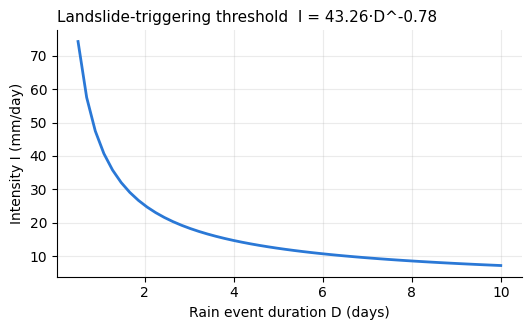

In [2]:
D = np.linspace(0.5, 10, 50)
fig, ax = plt.subplots(figsize=(6,3.2))
ax.plot(D, id_threshold(D), color='#2a78d6', lw=2)
ax.set_xlabel('Rain event duration D (days)'); ax.set_ylabel('Intensity I (mm/day)')
ax.set_title('Landslide-triggering threshold  I = 43.26·D^-0.78', loc='left', fontsize=11)
ax.grid(alpha=.25); ax.spines[['top','right']].set_visible(False); plt.show()

## 2. Train XGBoost and compare against two baselines

In [3]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve
from backend.risk.train import MONOTONE
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)
cons = '(' + ','.join(str(MONOTONE.get(f, 0)) for f in FEATURES) + ')'
clf = xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9, colsample_bytree=0.9,
                        min_child_weight=5, monotone_constraints=cons, tree_method='hist').fit(Xtr, ytr)
lr = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
p_x = clf.predict_proba(Xte)[:,1]; p_l = lr.predict_proba(Xte)[:,1]
p_rule = np.clip(Xte[:, FEATURES.index('id_ratio')] / 3, 0, 1)
rows = []
for name, p in [('XGBoost (monotone)', p_x), ('Logistic regression', p_l), ('Rainfall-threshold rule', p_rule)]:
    rows.append((name, roc_auc_score(yte, p), average_precision_score(yte, p), brier_score_loss(yte, p)))
print(f"{'model':28s} {'ROC-AUC':>8s} {'PR-AUC':>8s} {'Brier':>8s}")
for r in rows: print(f"{r[0]:28s} {r[1]:8.3f} {r[2]:8.3f} {r[3]:8.4f}")

model                         ROC-AUC   PR-AUC    Brier
XGBoost (monotone)              0.957    0.662   0.0180
Logistic regression             0.942    0.610   0.0194
Rainfall-threshold rule         0.811    0.114   0.2496


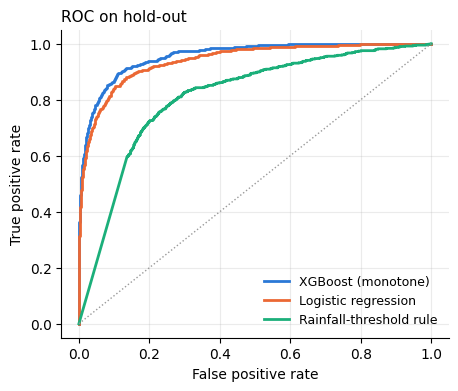

In [4]:
fig, ax = plt.subplots(figsize=(5,4))
for (name, p), col in zip([('XGBoost (monotone)', p_x), ('Logistic regression', p_l), ('Rainfall-threshold rule', p_rule)],
                          ['#2a78d6', '#eb6834', '#1baf7a']):
    f, t, _ = roc_curve(yte, p); ax.plot(f, t, color=col, lw=2, label=name)
ax.plot([0,1],[0,1], color='#999', lw=1, ls=':')
ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC on hold-out', loc='left', fontsize=11)
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=.25); ax.spines[['top','right']].set_visible(False); plt.show()

## 3. Calibration: do predicted probabilities mean what they say?
The router multiplies H(e,t) by delay hours, so calibration matters more than raw AUC.

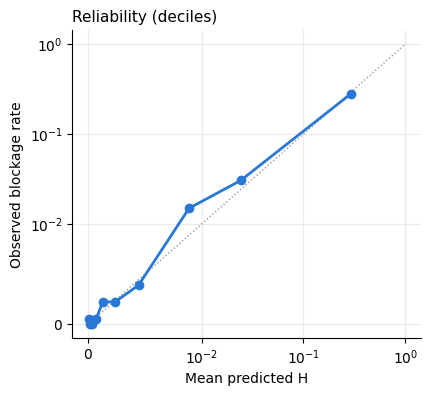

In [5]:
bins = np.quantile(p_x, np.linspace(0,1,11)); bins[0]=0; bins[-1]=1
idx = np.digitize(p_x, bins[1:-1])
mp = [p_x[idx==i].mean() for i in range(10)]; ob = [yte[idx==i].mean() for i in range(10)]
fig, ax = plt.subplots(figsize=(4.5,4))
ax.plot([0,1],[0,1], color='#999', lw=1, ls=':')
ax.plot(mp, ob, 'o-', color='#2a78d6', lw=2, ms=6)
ax.set_xscale('symlog', linthresh=0.01); ax.set_yscale('symlog', linthresh=0.01)
ax.set_xlabel('Mean predicted H'); ax.set_ylabel('Observed blockage rate'); ax.set_title('Reliability (deciles)', loc='left', fontsize=11)
ax.grid(alpha=.25); ax.spines[['top','right']].set_visible(False); plt.show()

## 4. What drives the model (mean |TreeSHAP| contribution)

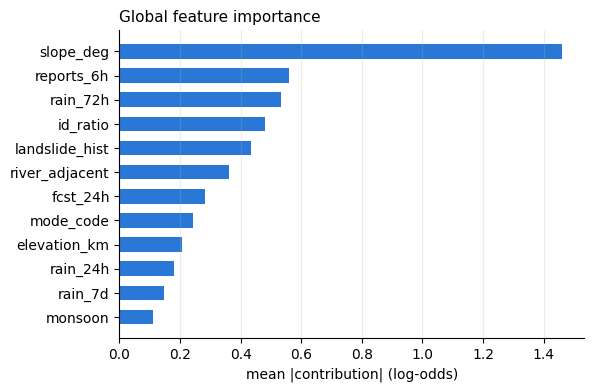

In [6]:
contrib = clf.get_booster().predict(xgb.DMatrix(Xte[:5000]), pred_contribs=True)[:, :-1]
imp = np.abs(contrib).mean(0); order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(6,4))
ax.barh([FEATURES[i] for i in order], imp[order], color='#2a78d6', height=0.6)
ax.set_xlabel('mean |contribution| (log-odds)'); ax.set_title('Global feature importance', loc='left', fontsize=11)
ax.spines[['top','right']].set_visible(False); ax.grid(axis='x', alpha=.25); plt.show()

## 5. Hotspots under each rainfall scenario (the production model)

In [7]:
from backend.weather import WeatherState, SCENARIOS
from backend.risk.model import HazardModel
M = HazardModel(); W = WeatherState(net['met_zones'])
E = {e['id']: e for e in net['edges']}
pick = ['SVK-TBZ','GRB-LAV','KHL-SNP','UMR-HRJ','NGB-NNY','CHM-PPH','KLS-AZL','BHK-BMD','LMD-NHF-rail','JRB-NGP','BNG-GHY']
print(f"{'edge':14s}" + ''.join(f'{k[:13]:>15s}' for k in SCENARIOS))
for eid in pick:
    out = []
    for k in SCENARIOS:
        W.set_scenario(k); s = M.score_all([E[eid]], W, {}, {})
        out.append(s[eid]['p_now'])
    print(f'{eid:14s}' + ''.join(f'{p:15.1%}' for p in out))

edge               dry_winter  normal_monsoo  barak_extreme  teesta_extrem  kameng_extrem
SVK-TBZ                  1.0%           7.6%           2.6%          90.5%           3.2%
GRB-LAV                  0.3%           1.6%           0.7%          28.0%           0.9%
KHL-SNP                  0.9%          21.8%          77.8%           3.9%           3.0%
UMR-HRJ                  1.0%           7.5%          85.5%           4.1%           3.2%
NGB-NNY                  1.1%           4.4%          62.2%           4.3%           3.4%
CHM-PPH                  0.5%           2.1%           6.0%           2.1%           1.8%
KLS-AZL                  0.9%           3.9%          35.4%           2.8%           2.3%
BHK-BMD                  0.9%           2.7%           1.6%           2.6%          62.8%
LMD-NHF-rail             0.3%           1.4%          32.5%           0.8%           0.7%
JRB-NGP                  0.1%           0.5%           1.9%           0.2%           0.2%
BNG-GHY   

## 6. One explained alert (what the dispatcher sees)

In [8]:
W.set_scenario('teesta_extreme')
ex = M.explain(E['SVK-TBZ'], W.for_edge(E['SVK-TBZ']['met_zones']), 0, W.month, 0.8)
print(ex['headline']); print('H =', ex['p'], '| confidence', ex['confidence'])
for f in ex['factors']: print(f"  {f['label']:22s} {f['logodds']:+.2f}  {f['detail']}")

High-risk edge: rainfall + steep terrain + landslide history
H = 0.9051 | confidence {'score': 0.64, 'label': 'Medium', 'basis': 'scenario rainfall'}
  Rainfall               +3.23  175 mm/24 h, 410 mm/72 h (7.4× the I-D landslide threshold); 150 mm more forecast
  Steep terrain          +1.58  33° mean slope, hill section
  Landslide history      +0.77  26 mapped slides within 1 km
  River-bank alignment   +0.51  road bed along the Teesta
  Transport mode         -0.01  
  Driver reports         -0.42  


## 7. KPI replay: risk-aware vs shortest-path routing
Same simulated world for both routers (common random numbers). The baseline sees only static travel times and learns of a blockage when it reaches it.

In [9]:
import tempfile, os
from backend.engine import Engine
from backend.sim import run_replay
eng = Engine(db_path=os.path.join(tempfile.mkdtemp(), 'nb.db'))
SEEDS = range(1, 6)   # 5 seeds x 400 trials: single runs are noisy, so report mean ± sd
keys = [('delay_avoided_pct', 'delay avoided %'), ('blockage_encounter_baseline_pct', 'encounters base %'),
        ('blockage_encounter_risk_aware_pct', 'encounters aware %'), ('eta_error_baseline_pct', 'ETA err base %'),
        ('eta_error_risk_aware_pct', 'ETA err aware %'), ('p90_trip_baseline_h', 'P90 base h'), ('p90_trip_risk_aware_h', 'P90 aware h'),
        ('cold_chain_breaches_baseline', 'breaches base'), ('cold_chain_breaches_risk_aware', 'breaches aware')]
results = {}
for sc, cargo in [('dry_winter','general'), ('normal_monsoon','general'), ('normal_monsoon','pharma'),
                  ('teesta_extreme','general'), ('barak_extreme','general'), ('kameng_extreme','general')]:
    runs = [run_replay(eng, sc, trials=400, cargo=cargo, seed=s) for s in SEEDS]
    results[(sc, cargo)] = {k: (np.mean([r[k] for r in runs]), np.std([r[k] for r in runs])) for k, _ in keys if k in runs[0]}
for (sc, cargo), r in results.items():
    print(); print(f"{sc} · {cargo}")
    for k, label in keys:
        if k in r: print(f"   {label:20s} {r[k][0]:8.1f} ± {r[k][1]:.1f}")


dry_winter · general
   delay avoided %          -0.0 ± 0.4
   encounters base %         3.4 ± 1.0
   encounters aware %        3.2 ± 0.8
   ETA err base %            1.9 ± 0.6
   ETA err aware %           3.7 ± 0.4
   P90 base h               20.7 ± 1.2
   P90 aware h              20.7 ± 1.2

normal_monsoon · general
   delay avoided %           3.3 ± 5.8
   encounters base %        16.3 ± 1.5
   encounters aware %       10.5 ± 1.5
   ETA err base %           14.2 ± 0.6
   ETA err aware %          12.9 ± 0.2
   P90 base h               28.5 ± 1.8
   P90 aware h              25.4 ± 0.2

normal_monsoon · pharma
   delay avoided %         -29.8 ± 10.3
   encounters base %        16.3 ± 1.5
   encounters aware %        6.5 ± 1.1
   ETA err base %           14.2 ± 0.6
   ETA err aware %           9.0 ± 0.2
   P90 base h               28.5 ± 1.8
   P90 aware h              26.5 ± 0.0
   breaches base            22.0 ± 3.5
   breaches aware            9.2 ± 1.2

teesta_extreme · general
   

### Reading the replay honestly
* **Dry season:** both routers pick the same paths, as they should. The risk-aware ETA is slightly pessimistic because it always prices in a small expected delay.
* **Normal monsoon, general cargo:** the recommended (risk-neutral Balanced) route cuts blockage encounters by about a third, lowers ETA error and P90, and does not lose mean time.
* **Normal monsoon, cold-chain cargo:** the recommendation deliberately weights the tail (P90) and the safe-transit limit. Temperature-breach trips fall from about 22 to 9 per 400. The price is a longer *mean* trip, because safer routes are longer. That trade is a policy choice, set by the perishability weight *k* and the tail weight in `backend/routing.py::recommend`.
* **Regional extremes:** gains in mean delay are 4–10%. In the Barak valley 2022 pattern every corridor into the valley is threatened, so no router finds a clean path. The value there is an honest ETA and early *hold / hand-over* advice. A departure-time option (wait at the hub for clearance) is the natural next feature.
* Single 400-trial runs are noisy (see the ± values), so always compare over several seeds.
* **Next step:** replace the generator with replayed real closures (NHIDCL/PWD logs, news-scraped closures, NASA COOLR/GSI inventory) and report these same KPIs.